# Credit Card Default Prediction

Predict which credit-card clients will default next month, from their credit limit, demographics and six months of repayment history. The classes are imbalanced (about 22% default), so the notebook compares plain classifiers with imbalance-aware ones and judges them on recall, F1 and ROC AUC on a held-out test set, not on accuracy.

**Data:** *Default of Credit Card Clients* (Taiwan, 2005), 30,000 clients, from the [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients), CC BY 4.0. Yeh, I. C. and Lien, C. H. (2009), *Expert Systems with Applications* 36(2).

## Variables

- **LIMIT_BAL**: credit granted (NT dollars), individual plus family credit.
- **SEX** (1 = male, 2 = female), **EDUCATION** (1 = graduate school, 2 = university, 3 = high school, 4 = others), **MARRIAGE** (1 = married, 2 = single, 3 = others), **AGE**.
- **PAY_1 … PAY_6**: repayment status from September back to April 2005. -2 = no consumption, -1 = paid in full, 0 = revolving credit, 1-9 = months of payment delay.
- **BILL_AMT1 … BILL_AMT6**: bill statement amounts, same months.
- **PAY_AMT1 … PAY_AMT6**: amounts paid, same months.
- **TARGET**: default in the following month (1 = yes).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import metrics
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline as sk_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from imblearn.ensemble import BalancedBaggingClassifier, BalancedRandomForestClassifier
from imblearn.pipeline import make_pipeline
from imblearn.under_sampling import RandomUnderSampler

SEED = 2022
sns.set_theme(style="whitegrid")

## Helpers

In [2]:
def performance(model, X_train, y_train, X_test, y_test):
    """Accuracy, precision, recall, F1 and ROC AUC on train and test.
    Every sklearn metric is called as metric(y_true, y_pred)."""
    rows = {}
    for split, X, y in [("Train", X_train, y_train), ("Test", X_test, y_test)]:
        pred = model.predict(X)
        proba = model.predict_proba(X)[:, 1]
        rows[split] = {
            "Accuracy": metrics.accuracy_score(y, pred),
            "Precision": metrics.precision_score(y, pred),
            "Recall": metrics.recall_score(y, pred),
            "F1": metrics.f1_score(y, pred),
            "ROC AUC": metrics.roc_auc_score(y, proba),
        }
    return pd.DataFrame(rows)


def plot_confusion(model, X_test, y_test, title):
    cm = metrics.confusion_matrix(y_test, model.predict(X_test))
    names = ["True neg", "False pos", "False neg", "True pos"]
    labels = [f"{n}\n{c:,}\n{c / cm.sum():.1%}" for n, c in zip(names, cm.flatten())]
    plt.figure(figsize=(4.5, 3.5))
    sns.heatmap(cm, annot=np.array(labels).reshape(2, 2), fmt="", cmap="Blues", cbar=False)
    plt.ylabel("True label")
    plt.xlabel("Predicted label")
    plt.title(title)
    plt.show()


results = {}

def evaluate(name, model):
    model.fit(X_train, y_train)
    table = performance(model, X_train, y_train, X_test, y_test)
    results[name] = table["Test"]
    print(metrics.classification_report(y_test, model.predict(X_test), digits=3))
    plot_confusion(model, X_test, y_test, name)
    return table

## Loading the data

In [3]:
# The first row of the sheet holds the real column names.
ds = pd.read_excel("data/default_credit_card_clients.xlsx", header=1)
ds = ds.drop(columns=["ID"]).rename(columns={"PAY_0": "PAY_1", "default payment next month": "TARGET"})
print(ds.shape)
print("duplicated rows:", ds.duplicated().sum(), "| missing values:", ds.isna().sum().sum())
ds.describe().T

(30000, 24)
duplicated rows: 35 | missing values: 0


,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_1,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0
PAY_5,30000.0,-0.266200,1.133187,-2.0,-1.00,0.0,0.00,8.0


## Exploration

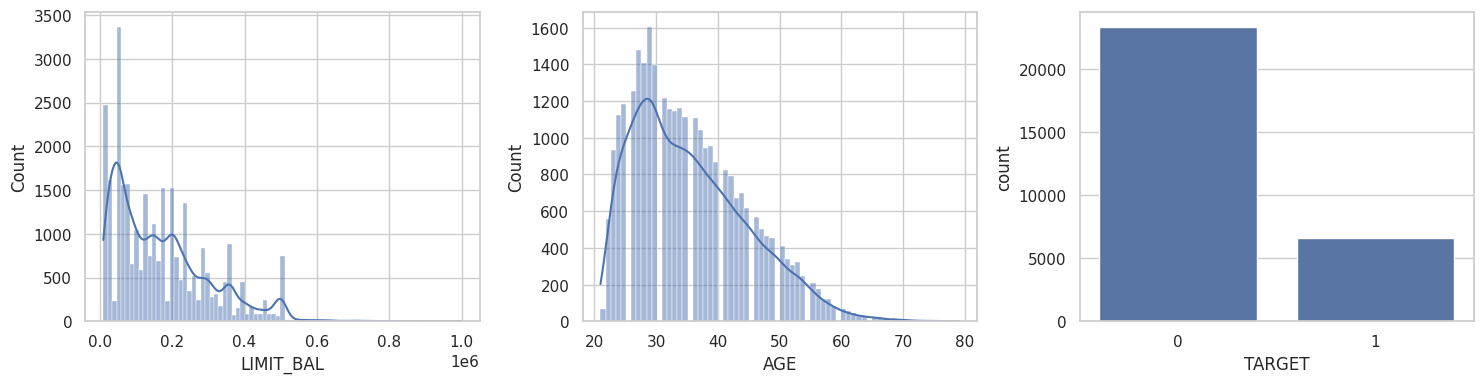

LIMIT_BAL skew: 0.99 | AGE skew: 0.73


TARGET
0    0.7788
1    0.2212
Name: proportion, dtype: float64

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(data=ds, x="LIMIT_BAL", kde=True, ax=axes[0])
sns.histplot(data=ds, x="AGE", kde=True, ax=axes[1])
sns.countplot(data=ds, x="TARGET", ax=axes[2])
plt.tight_layout()
plt.show()
print("LIMIT_BAL skew:", round(ds["LIMIT_BAL"].skew(), 2), "| AGE skew:", round(ds["AGE"].skew(), 2))
ds["TARGET"].value_counts(normalize=True)

Credit limits are right-skewed and about 22% of clients default, so accuracy alone would reward predicting "no default" for everyone.

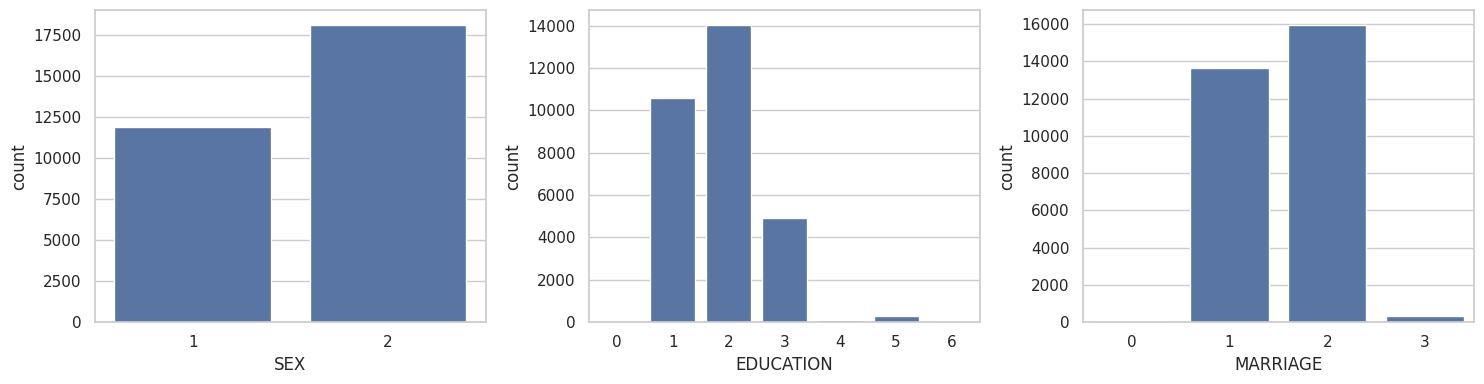

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for col, ax in zip(["SEX", "EDUCATION", "MARRIAGE"], axes):
    sns.countplot(data=ds, x=col, ax=ax)
plt.tight_layout()
plt.show()

EDUCATION has codes 0, 5 and 6 and MARRIAGE has code 0, none of which the data description defines. Those rows are dropped.

In [6]:
ds = ds[~ds["EDUCATION"].isin([0, 5, 6]) & (ds["MARRIAGE"] != 0)]
ds.shape

(29601, 24)

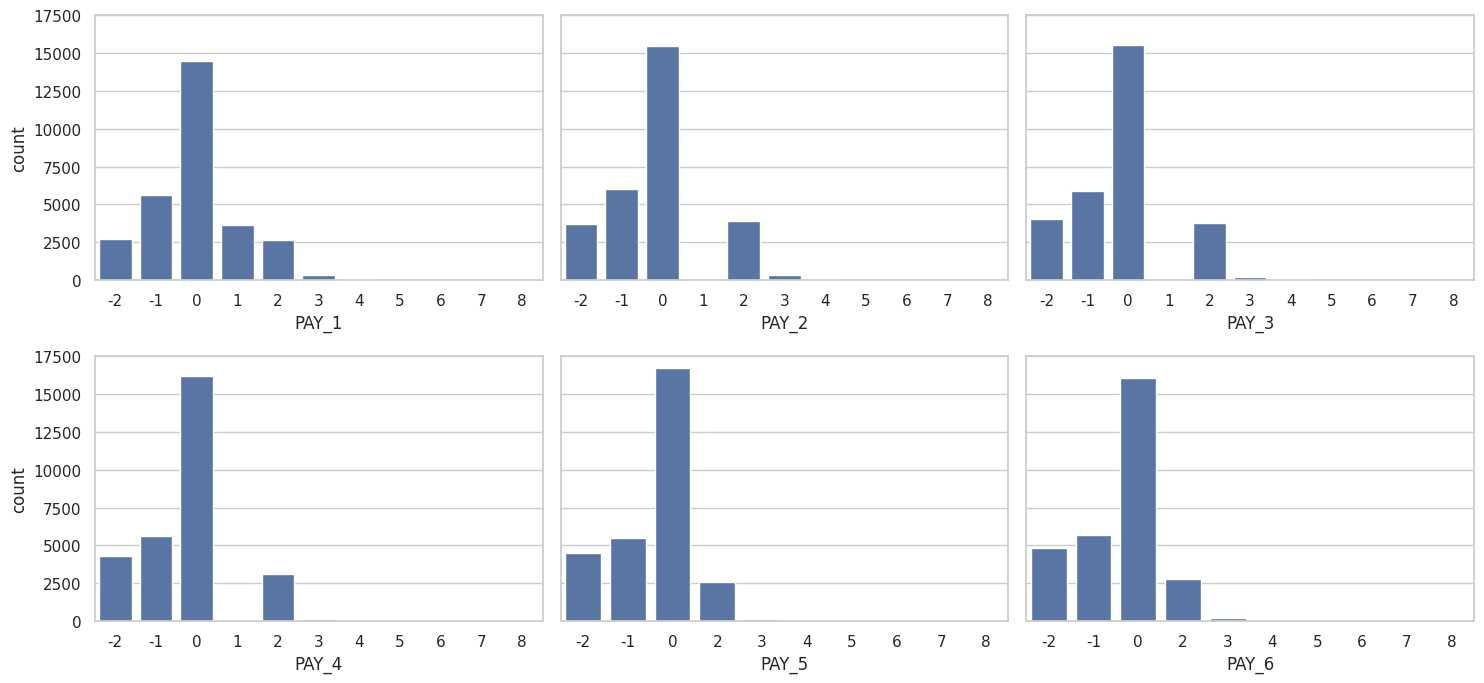

In [7]:
pay = [f"PAY_{i}" for i in range(1, 7)]
fig, axes = plt.subplots(2, 3, sharey=True, figsize=(15, 7))
for col, ax in zip(pay, axes.flatten()):
    sns.countplot(data=ds, x=col, ax=ax)
plt.tight_layout()
plt.show()

In the repayment-status columns, -2 means no consumption that month. It is a valid state, so those rows are kept.

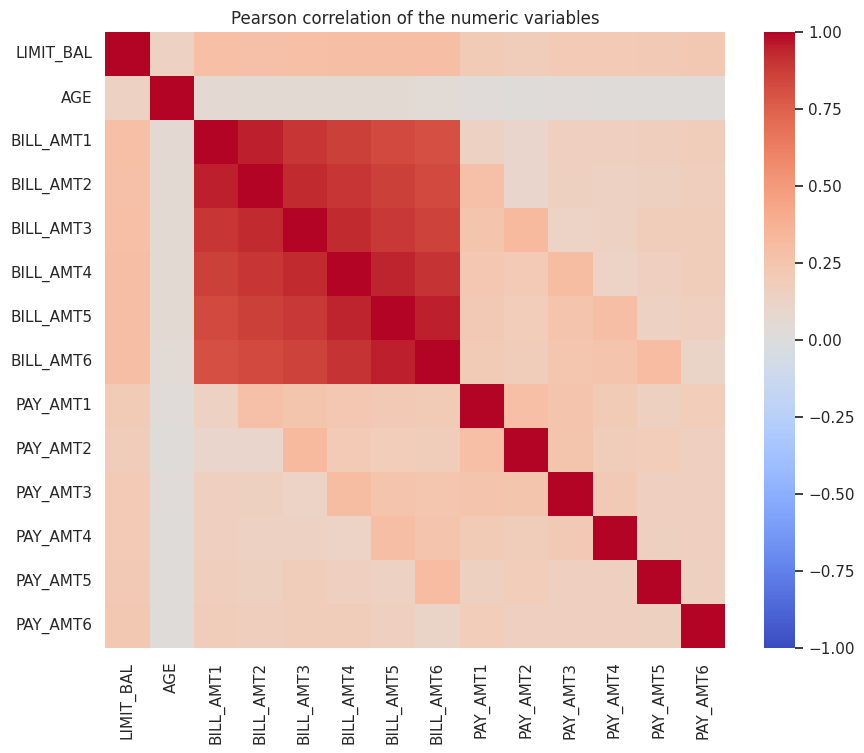

In [8]:
bill = [f"BILL_AMT{i}" for i in range(1, 7)]
pay_amt = [f"PAY_AMT{i}" for i in range(1, 7)]
plt.figure(figsize=(10, 8))
sns.heatmap(ds[["LIMIT_BAL", "AGE"] + bill + pay_amt].corr(), cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Pearson correlation of the numeric variables")
plt.show()

The six bill amounts are highly correlated with each other, so they are replaced by their mean. Payment amounts are heavily right-skewed, so they enter as `log1p`.

In [9]:
for col in pay_amt:
    print(f"{col}: skew {ds[col].skew():6.2f} -> log1p skew {np.log1p(ds[col]).skew():5.2f}")

PAY_AMT1: skew  14.77 -> log1p skew -1.29
PAY_AMT2: skew  30.63 -> log1p skew -1.24
PAY_AMT3: skew  17.42 -> log1p skew -1.08
PAY_AMT4: skew  12.93 -> log1p skew -0.97
PAY_AMT5: skew  11.19 -> log1p skew -0.94
PAY_AMT6: skew  10.82 -> log1p skew -0.86


## Data preparation

In [10]:
X = ds.copy()
X["BILL_AMT"] = X[bill].mean(axis=1)
for col in pay_amt:
    X[f"LOG_{col}"] = np.log1p(X[col])
X = X.drop(columns=bill + pay_amt)

y = X.pop("TARGET")
categorical = ["SEX", "EDUCATION", "MARRIAGE"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=True, stratify=y, random_state=SEED)

# One-hot encode the categorical columns, fitted on train only.
encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore").fit(X_train[categorical])

def encode(frame):
    dummies = pd.DataFrame(encoder.transform(frame[categorical]),
                           columns=encoder.get_feature_names_out(categorical), index=frame.index)
    return pd.concat([frame.drop(columns=categorical), dummies], axis=1)

X_train, X_test = encode(X_train), encode(X_test)
print(X_train.shape, X_test.shape)
y_train.value_counts(normalize=True)

(23680, 24) (5921, 24)


TARGET
0    0.776858
1    0.223142
Name: proportion, dtype: float64

## Models
### Logistic regression (standardised features)

              precision    recall  f1-score   support

           0      0.820     0.963     0.886      4600
           1      0.674     0.263     0.378      1321

    accuracy                          0.807      5921
   macro avg      0.747     0.613     0.632      5921
weighted avg      0.787     0.807     0.773      5921



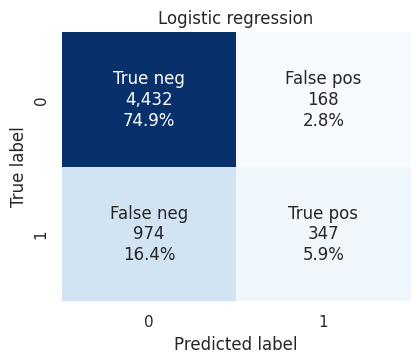

,Train,Test
Accuracy,0.806081,0.807127
Precision,0.680585,0.673786
Recall,0.246783,0.262680
F1,0.362222,0.377996
ROC AUC,0.747539,0.748915


In [11]:
evaluate("Logistic regression", sk_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED)))

### Random forest

              precision    recall  f1-score   support

           0      0.840     0.949     0.891      4600
           1      0.676     0.371     0.479      1321

    accuracy                          0.820      5921
   macro avg      0.758     0.660     0.685      5921
weighted avg      0.803     0.820     0.799      5921



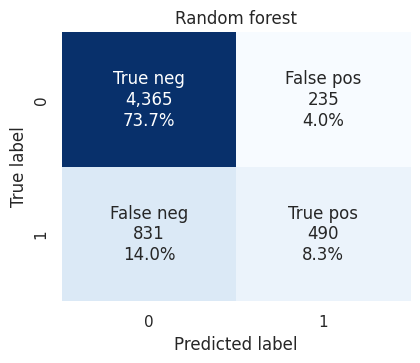

,Train,Test
Accuracy,0.851478,0.819963
Precision,0.810327,0.675862
Recall,0.436601,0.370931
F1,0.567458,0.478983
ROC AUC,0.847189,0.778105


In [12]:
evaluate("Random forest", RandomForestClassifier(max_depth=10, random_state=SEED, n_jobs=-1))

Both plain models predict "no default" for most clients and miss many defaulters. The next models correct for the imbalance.

### Balanced random forest
Each tree is grown on a bootstrap sample under-sampled to balance the classes.

              precision    recall  f1-score   support

           0      0.879     0.824     0.851      4600
           1      0.498     0.606     0.546      1321

    accuracy                          0.776      5921
   macro avg      0.688     0.715     0.699      5921
weighted avg      0.794     0.776     0.783      5921



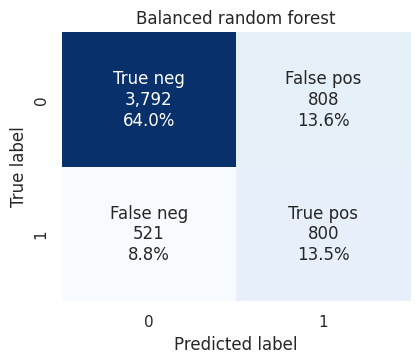

,Train,Test
Accuracy,0.810726,0.775545
Precision,0.562228,0.497512
Recall,0.685655,0.605602
F1,0.617838,0.546262
ROC AUC,0.849575,0.781918


In [13]:
evaluate("Balanced random forest", BalancedRandomForestClassifier(
    max_depth=10, sampling_strategy="all", replacement=True, bootstrap=False, random_state=SEED, n_jobs=-1))

### Balanced bagging

              precision    recall  f1-score   support

           0      0.868     0.846     0.857      4600
           1      0.507     0.551     0.528      1321

    accuracy                          0.780      5921
   macro avg      0.687     0.699     0.692      5921
weighted avg      0.787     0.780     0.783      5921



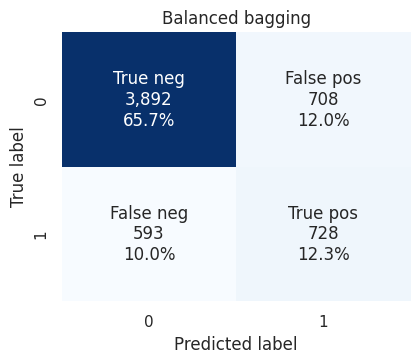

,Train,Test
Accuracy,0.947593,0.780274
Precision,0.809808,0.506964
Recall,1.000000,0.551098
F1,0.894911,0.528110
ROC AUC,0.996793,0.760056


In [14]:
evaluate("Balanced bagging", BalancedBaggingClassifier(n_estimators=50, random_state=SEED, n_jobs=-1))

### Random under-sampling + random forest

              precision    recall  f1-score   support

           0      0.881     0.803     0.840      4600
           1      0.476     0.624     0.540      1321

    accuracy                          0.763      5921
   macro avg      0.679     0.713     0.690      5921
weighted avg      0.791     0.763     0.773      5921



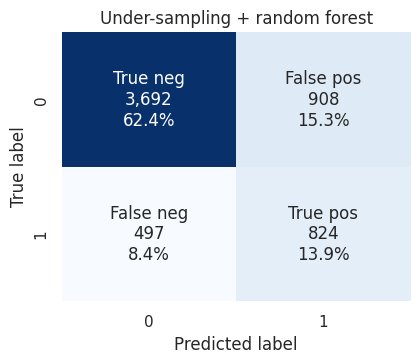

,Train,Test
Accuracy,0.795481,0.762709
Precision,0.531887,0.475751
Recall,0.696064,0.623770
F1,0.603000,0.539797
ROC AUC,0.836737,0.780064


In [15]:
evaluate("Under-sampling + random forest", make_pipeline(
    RandomUnderSampler(random_state=SEED),
    RandomForestClassifier(n_estimators=500, max_depth=10, min_samples_split=8, random_state=SEED, n_jobs=-1)))

### Random under-sampling + gradient boosting

              precision    recall  f1-score   support

           0      0.883     0.790     0.834      4600
           1      0.465     0.634     0.537      1321

    accuracy                          0.756      5921
   macro avg      0.674     0.712     0.685      5921
weighted avg      0.790     0.756     0.768      5921



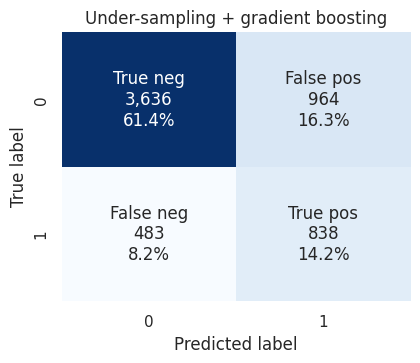

,Train,Test
Accuracy,0.768877,0.755616
Precision,0.486741,0.465039
Recall,0.656510,0.634368
F1,0.559020,0.536663
ROC AUC,0.800316,0.781514


In [16]:
evaluate("Under-sampling + gradient boosting", make_pipeline(
    RandomUnderSampler(random_state=SEED),
    GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, random_state=SEED)))

## Comparison on the test set

In [17]:
summary = pd.DataFrame(results).T.sort_values("F1", ascending=False)
summary.round(3)

,Accuracy,Precision,Recall,F1,ROC AUC
Balanced random forest,0.776,0.498,0.606,0.546,0.782
Under-sampling + random forest,0.763,0.476,0.624,0.540,0.780
Under-sampling + gradient boosting,0.756,0.465,0.634,0.537,0.782
Balanced bagging,0.780,0.507,0.551,0.528,0.760
Random forest,0.820,0.676,0.371,0.479,0.778
Logistic regression,0.807,0.674,0.263,0.378,0.749


In [18]:
# Sanity checks: every model ran, and the best one ranks clients clearly better than chance.
assert len(summary) == 6
assert summary["ROC AUC"].max() > 0.7

## Conclusion

- **Accuracy misleads here.** The plain random forest has the best accuracy (0.82) but finds only 37% of defaulters; logistic regression finds 26%.
- **Re-balancing doubles recall.** The balanced random forest catches 61% of defaulters with the best F1 (0.55), and both under-sampling pipelines reach 62-63% recall, at the cost of more false alarms (precision about 0.47-0.50).
- **Ranking quality is similar.** ROC AUC is 0.78 for every tree ensemble except balanced bagging (0.76), which also overfits (train AUC 0.997).
- **Recommendation:** the balanced random forest, with its decision threshold set from the bank's relative cost of a missed default versus a false alarm.
